In [1]:
import gym
import numpy as np
import gym_mppt
from gym import envs

import os
models_dir = "models/SAC"
logdir = "logs"

if not os.path.exists(models_dir):
    os.makedirs(models_dir)
    
if not os.path.exists(logdir):
    os.makedirs(logdir)    

In [2]:
env = gym.make("mppt_shaded-v2")

num_states = len(env.observation_space)
print("Size of State Space ->  {}".format(num_states))
print(env.observation_space)

print()

num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))
print(env.action_space)

upper_bound = env.action_space.high[0]
lower_bound = env.action_space.low[0]

print("Max Value of Action ->  {}".format(upper_bound))
print("Min Value of Action ->  {}".format(lower_bound))

Size of State Space ->  3
Dict(Power:Box([0.], [inf], (1,), float32), Voltage:Box([0.], [212.], (1,), float32), deltaPower:Box([-inf], [inf], (1,), float32))

Size of Action Space ->  1
Box([-212.], [212.], (1,), float32)
Max Value of Action ->  212.0
Min Value of Action ->  -212.0


In [3]:
from stable_baselines3 import SAC
from stable_baselines3.common.noise import NormalActionNoise, OrnsteinUhlenbeckActionNoise

In [4]:
n_actions = env.action_space.shape[-1]
action_noise = NormalActionNoise(mean=np.zeros(n_actions), sigma=0.1 * np.ones(n_actions))

tensorboard_log = os.path.join(logdir, "tensorboard")
model = SAC("MultiInputPolicy", env, verbose=1, learning_rate=0.000001, tensorboard_log=tensorboard_log)
TIMESTEPS = 5000001
model.learn(total_timesteps=TIMESTEPS, log_interval=10, progress_bar=True, reset_num_timesteps=False, tb_log_name="SAC-successor5")
model.save(f"{models_dir}/{TIMESTEPS}")
env = model.get_env()

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to logs/tensorboard/SAC-successor5_0


Output()

/home/ws10/Documents/PVCell-Torch/PVCellRLTorch-main/mppt-gym_v2/gym_mppt/envs/mppt_env_shaded2.py:37: 
RuntimeWarning: overflow encountered in exp
  I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 14.5     |
| time/              |          |
|    episodes        | 10       |
|    fps             | 30       |
|    time_elapsed    | 32       |
|    total_timesteps | 1000     |
| train/             |          |
|    actor_loss      | 232      |
|    critic_loss     | 2.32e+04 |
|    ent_coef        | 1        |
|    ent_coef_loss   | -0.00976 |
|    learning_rate   | 1e-06    |
|    n_updates       | 899      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 9.49     |
| time/              |          |
|    episodes        | 20       |
|    fps             | 29       |
|    time_elapsed    | 67       |
|    total_timesteps | 2000     |
| train/             |          |
|    actor_loss      | 156      |
|    critic_loss     | 1.19e+04 |
|    ent_coef 

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 3.01     |
| time/              |          |
|    episodes        | 160      |
|    fps             | 30       |
|    time_elapsed    | 529      |
|    total_timesteps | 16000    |
| train/             |          |
|    actor_loss      | 10.6     |
|    critic_loss     | 119      |
|    ent_coef        | 1.01     |
|    ent_coef_loss   | -0.00719 |
|    learning_rate   | 1e-06    |
|    n_updates       | 15899    |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 2.99     |
| time/              |          |
|    episodes        | 170      |
|    fps             | 30       |
|    time_elapsed    | 562      |
|    total_timesteps | 17000    |
| train/             |          |
|    actor_loss      | 8.37     |
|    critic_loss     | 100      |
|    ent_coef 

...

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 26.1     |
| time/              |          |
|    episodes        | 49260    |
|    fps             | 31       |
|    time_elapsed    | 158123   |
|    total_timesteps | 4926000  |
| train/             |          |
|    actor_loss      | -7.45    |
|    critic_loss     | 0.753    |
|    ent_coef        | 0.0457   |
|    ent_coef_loss   | 0.935    |
|    learning_rate   | 1e-06    |
|    n_updates       | 4925899  |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 25.5     |
| time/              |          |
|    episodes        | 49270    |
|    fps             | 31       |
|    time_elapsed    | 158152   |
|    total_timesteps | 4927000  |
| train/             |          |
|    actor_loss      | -7.63    |
|    critic_loss     | 1.22     |
|    ent_coef 

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 23.5     |
| time/              |          |
|    episodes        | 49410    |
|    fps             | 31       |
|    time_elapsed    | 158526   |
|    total_timesteps | 4941000  |
| train/             |          |
|    actor_loss      | -7.58    |
|    critic_loss     | 0.608    |
|    ent_coef        | 0.0458   |
|    ent_coef_loss   | -0.428   |
|    learning_rate   | 1e-06    |
|    n_updates       | 4940899  |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 23.8     |
| time/              |          |
|    episodes        | 49420    |
|    fps             | 31       |
|    time_elapsed    | 158556   |
|    total_timesteps | 4942000  |
| train/             |          |
|    actor_loss      | -7.53    |
|    critic_loss     | 1.54     |
|    ent_coef 

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 25.4     |
| time/              |          |
|    episodes        | 49560    |
|    fps             | 31       |
|    time_elapsed    | 158953   |
|    total_timesteps | 4956000  |
| train/             |          |
|    actor_loss      | -7.5     |
|    critic_loss     | 0.829    |
|    ent_coef        | 0.046    |
|    ent_coef_loss   | -0.442   |
|    learning_rate   | 1e-06    |
|    n_updates       | 4955899  |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 25.4     |
| time/              |          |
|    episodes        | 49570    |
|    fps             | 31       |
|    time_elapsed    | 158983   |
|    total_timesteps | 4957000  |
| train/             |          |
|    actor_loss      | -7.64    |
|    critic_loss     | 0.747    |
|    ent_coef 

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 25.8     |
| time/              |          |
|    episodes        | 49710    |
|    fps             | 31       |
|    time_elapsed    | 159402   |
|    total_timesteps | 4971000  |
| train/             |          |
|    actor_loss      | -7.34    |
|    critic_loss     | 1.12     |
|    ent_coef        | 0.0461   |
|    ent_coef_loss   | 0.957    |
|    learning_rate   | 1e-06    |
|    n_updates       | 4970899  |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 25.7     |
| time/              |          |
|    episodes        | 49720    |
|    fps             | 31       |
|    time_elapsed    | 159431   |
|    total_timesteps | 4972000  |
| train/             |          |
|    actor_loss      | -7.69    |
|    critic_loss     | 0.966    |
|    ent_coef 

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 26.7     |
| time/              |          |
|    episodes        | 49860    |
|    fps             | 31       |
|    time_elapsed    | 159845   |
|    total_timesteps | 4986000  |
| train/             |          |
|    actor_loss      | -7.73    |
|    critic_loss     | 1.04     |
|    ent_coef        | 0.0463   |
|    ent_coef_loss   | 0.805    |
|    learning_rate   | 1e-06    |
|    n_updates       | 4985899  |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 27       |
| time/              |          |
|    episodes        | 49870    |
|    fps             | 31       |
|    time_elapsed    | 159875   |
|    total_timesteps | 4987000  |
| train/             |          |
|    actor_loss      | -7.61    |
|    critic_loss     | 0.681    |
|    ent_coef 

In [6]:
for i in range(10):
    obs = env.reset()
#     print(env.buf_infos)
    for j in range(100):
        action, _states = model.predict(obs)
        obs, rewards, dones, info = env.step(action)
        print(obs)
        print(rewards)
    print()

OrderedDict([('Power', array([[12443.33]], dtype=float32)), ('Voltage', array([[124.71881]], dtype=float32)), ('deltaPower', array([[12443.33]], dtype=float32))])
[0.9980789]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[288.4507]], dtype=float32)), ('deltaPower', array([[-12443.33]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[8906.621]], dtype=float32)), ('Voltage', array([[80.29407]], dtype=float32)), ('deltaPower', array([[8906.621]], dtype=float32))])
[0.51134926]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[265.8687]], dtype=float32)), ('deltaPower', array([[-8906.621]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[7438.3765]], dtype=float32)), ('Voltage', array([[66.746414]], dtype=float32)), ('deltaPower', array([[7438.3765]], dtype=float32))])
[0.3566547]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[233.7881]], dtype=float32)), ('deltaPower', array([[-7438.3765]], dtype=flo

OrderedDict([('Power', array([[12144.639]], dtype=float32)), ('Voltage', array([[134.96005]], dtype=float32)), ('deltaPower', array([[12144.639]], dtype=float32))])
[0.9507379]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[270.3394]], dtype=float32)), ('deltaPower', array([[-12144.639]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[7058.0454]], dtype=float32)), ('Voltage', array([[63.2881]], dtype=float32)), ('deltaPower', array([[7058.0454]], dtype=float32))])
[0.32111496]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[254.42778]], dtype=float32)), ('deltaPower', array([[-7058.0454]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[10838.445]], dtype=float32)), ('Voltage', array([[53.620895]], dtype=float32)), ('deltaPower', array([[10838.445]], dtype=float32))])
[0.7572261]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[239.2972]], dtype=float32)), ('deltaPower', array([[-10838.445]], dty

OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[334.1292]], dtype=float32)), ('deltaPower', array([[-27499.787]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[26285.684]], dtype=float32)), ('Voltage', array([[134.49422]], dtype=float32)), ('deltaPower', array([[26285.684]], dtype=float32))])
[0.54907346]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[334.648]], dtype=float32)), ('deltaPower', array([[-26285.684]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[27454.186]], dtype=float32)), ('Voltage', array([[126.75456]], dtype=float32)), ('deltaPower', array([[27454.186]], dtype=float32))])
[0.5989755]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[332.07208]], dtype=float32)), ('deltaPower', array([[-27454.186]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[27257.877]], dtype=float32)), ('Voltage', array([[129.33478]], dtype=float32)), ('deltaPower', array([[27257.877]], dtype=flo

OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[271.15387]], dtype=float32)), ('deltaPower', array([[-17971.555]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[21628.215]], dtype=float32)), ('Voltage', array([[88.17581]], dtype=float32)), ('deltaPower', array([[21628.215]], dtype=float32))])
[0.5297196]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[246.81369]], dtype=float32)), ('deltaPower', array([[-21628.215]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[249.8002]], dtype=float32)), ('deltaPower', array([[0.]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[29422.756]], dtype=float32)), ('Voltage', array([[129.00223]], dtype=float32)), ('deltaPower', array([[29422.756]], dtype=float32))])
[0.9803279]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[334.50803]], dtype=float32)), ('deltaPower', array([[-29422.756]], dtype=float32))])
[0.]


OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[306.16254]], dtype=float32)), ('deltaPower', array([[-31203.479]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[30500.348]], dtype=float32)), ('Voltage', array([[102.82568]], dtype=float32)), ('deltaPower', array([[30500.348]], dtype=float32))])
[0.6984162]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[286.7587]], dtype=float32)), ('deltaPower', array([[-30500.348]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[27843.992]], dtype=float32)), ('Voltage', array([[93.25682]], dtype=float32)), ('deltaPower', array([[27843.992]], dtype=float32))])
[0.58206]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[284.96735]], dtype=float32)), ('deltaPower', array([[-27843.992]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[26737.293]], dtype=float32)), ('Voltage', array([[89.39386]], dtype=float32)), ('deltaPower', array([[26737.293]], dtype=float3

...

OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[369.67865]], dtype=float32)), ('deltaPower', array([[0.]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[181.58916]], dtype=float32)), ('deltaPower', array([[0.]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[3540.7485]], dtype=float32)), ('Voltage', array([[99.06325]], dtype=float32)), ('deltaPower', array([[3540.7485]], dtype=float32))])
[0.06422334]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[299.95966]], dtype=float32)), ('deltaPower', array([[-3540.7485]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[3811.441]], dtype=float32)), ('Voltage', array([[111.659485]], dtype=float32)), ('deltaPower', array([[3811.441]], dtype=float32))])
[0.07441854]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[295.58963]], dtype=float32)), ('deltaPower', array([[-3811.441]], dtype=float32))])
[0.]
Ordered

OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[346.28888]], dtype=float32)), ('deltaPower', array([[-8720.646]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[9449.268]], dtype=float32)), ('Voltage', array([[162.82811]], dtype=float32)), ('deltaPower', array([[9449.268]], dtype=float32))])
[0.3953158]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[357.65967]], dtype=float32)), ('deltaPower', array([[-9449.268]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[8633.512]], dtype=float32)), ('Voltage', array([[166.91534]], dtype=float32)), ('deltaPower', array([[8633.512]], dtype=float32))])
[0.33000678]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[369.1871]], dtype=float32)), ('deltaPower', array([[-8633.512]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[188.89703]], dtype=float32)), ('deltaPower', array([[0.]], dtype=float32))])
[0.]
Order

OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[361.94244]], dtype=float32)), ('deltaPower', array([[-8170.693]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[8223.876]], dtype=float32)), ('Voltage', array([[157.525]], dtype=float32)), ('deltaPower', array([[8223.876]], dtype=float32))])
[0.06712703]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[364.01096]], dtype=float32)), ('deltaPower', array([[-8223.876]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[176.33365]], dtype=float32)), ('deltaPower', array([[0.]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[28610.01]], dtype=float32)), ('Voltage', array([[97.57294]], dtype=float32)), ('deltaPower', array([[28610.01]], dtype=float32))])
[0.81241953]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[295.05347]], dtype=float32)), ('deltaPower', array([[-28610.01]], dtype=float32))])
[0.]
Ordere

OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[308.54825]], dtype=float32)), ('deltaPower', array([[-38686.75]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[9901.971]], dtype=float32)), ('Voltage', array([[155.41153]], dtype=float32)), ('deltaPower', array([[9901.971]], dtype=float32))])
[0.06441387]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[359.354]], dtype=float32)), ('deltaPower', array([[-9901.971]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[166.33473]], dtype=float32)), ('deltaPower', array([[0.]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[38977.184]], dtype=float32)), ('Voltage', array([[118.160095]], dtype=float32)), ('deltaPower', array([[38977.184]], dtype=float32))])
[0.9980608]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[319.3971]], dtype=float32)), ('deltaPower', array([[-38977.184]], dtype=float32))])
[0.]
Ord

OrderedDict([('Power', array([[37486.887]], dtype=float32)), ('Voltage', array([[100.50893]], dtype=float32)), ('deltaPower', array([[37486.887]], dtype=float32))])
[0.5381585]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[307.54468]], dtype=float32)), ('deltaPower', array([[-37486.887]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[47548.35]], dtype=float32)), ('Voltage', array([[131.12576]], dtype=float32)), ('deltaPower', array([[47548.35]], dtype=float32))])
[0.86580956]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[338.28302]], dtype=float32)), ('deltaPower', array([[-47548.35]], dtype=float32))])
[0.]
OrderedDict([('Power', array([[50948.168]], dtype=float32)), ('Voltage', array([[148.88564]], dtype=float32)), ('deltaPower', array([[50948.168]], dtype=float32))])
[0.9940508]
OrderedDict([('Power', array([[0.]], dtype=float32)), ('Voltage', array([[356.24628]], dtype=float32)), ('deltaPower', array([[-50948.168]], dt

In [8]:
for i in range(10):
    obs = env.reset()
#     print(env.buf_infos)
    for j in range(100):
        action, _states = model.predict(obs)
        obs, rewards, dones, info = env.step(action)
        print(obs["Power"][0])
        print(rewards)
    print()

[28628.062]
[0.9280869]
[0.]
[0.]
[28430.322]
[0.9153101]
[0.]
[0.]
[29707.912]
[0.999422]
[0.]
[0.]
[27583.596]
[0.86160153]
[0.]
[0.]
[28350.395]
[0.9101708]
[0.]
[0.]
[14149.51]
[0.22671877]
[0.]
[0.]
[20822.822]
[0.49100268]
[0.]
[0.]
[0.]
[0.]
[18900.576]
[0.40453374]
[0.]
[0.]
[29712.059]
[0.999701]
[0.]
[0.]
[26755.438]
[0.81064147]
[0.]
[0.]
[12676.492]
[0.1819713]
[0.]
[0.]
[14106.631]
[0.22534674]
[0.]
[0.]
[13882.772]
[0.21825142]
[0.]
[0.]
[23128.254]
[0.6057458]
[0.]
[0.]
[16128.26]
[0.29456404]
[0.]
[0.]
[24045.715]
[0.65475684]
[0.]
[0.]
[23741.43]
[0.6382906]
[0.]
[0.]
[15824.121]
[0.28355926]
[0.]
[0.]
[27946.62]
[0.8844295]
[0.]
[0.]
[28117.525]
[0.89528]
[0.]
[0.]
[27377.998]
[0.8488052]
[0.]
[0.]
[27652.84]
[0.8659327]
[0.]
[0.]
[25272.564]
[0.7232748]
[0.]
[0.]
[24011.717]
[0.6529067]
[0.]
[0.]
[26047.365]
[0.7683025]
[0.]
[0.]
[29697.77]
[0.9987398]
[0.]
[0.]
[28573.283]
[0.9245384]
[0.]
[0.]
[28829.201]
[0.94117403]
[0.]
[0.]
[26759.572]
[0.810892]
[0.]
[0.]
[289

[35625.344]
[0.8081535]
[0.]
[0.]
[34930.15]
[0.77692056]
[0.]
[0.]
[37456.93]
[0.893388]
[0.]
[0.]
[39599.445]
[0.9985135]
[0.]
[0.]
[12550.781]
[0.10030377]
[0.]
[0.]
[0.]
[0.]
[36900.52]
[0.86704314]
[0.]
[0.]
[38183.383]
[0.92837733]
[0.]
[0.]
[39025.004]
[0.9697541]
[0.]
[0.]
[38813.633]
[0.9592777]
[0.]
[0.]
[38787.816]
[0.958002]
[0.]
[0.]
[38832.59]
[0.96021485]
[0.]
[0.]
[39595.14]
[0.9982964]
[0.]
[0.]
[20139.]
[0.25825667]
[0.]
[0.]
[18911.822]
[0.22774166]
[0.]
[0.]
[18132.453]
[0.20935766]
[0.]
[0.]
[17925.438]
[0.20460455]
[0.]
[0.]
[29235.969]
[0.5442654]
[0.]
[0.]
[33770.773]
[0.72620255]
[0.]
[0.]
[33782.39]
[0.7267022]
[0.]
[0.]
[30689.451]
[0.5997276]
[0.]
[0.]
[20783.193]
[0.2750428]
[0.]
[0.]
[14990.371]
[0.1430871]
[0.]
[0.]
[4794.261]
[0.01463589]
[0.]
[0.]
[0.]
[0.]
[17399.102]
[0.19276555]
[0.]
[0.]
[16189.677]
[0.16689837]
[0.]
[0.]
[17727.568]
[0.20011245]
[0.]
[0.]
[7996.079]
[0.0407127]
[0.]
[0.]
[39054.164]
[0.971204]
[0.]
[0.]
[39436.438]
[0.99030983]
[0.

[{'Steps': 100, 'Current': 0, 'Temperature': 25.0, 'Irradiance': 1000.0, 'Shading': [6, 10, 5, 10, 1, 10], 'episode': {'r': 15.92429, 'l': 100, 't': 167484.3648}, 'terminal_observation': OrderedDict([('Power', array([0.], dtype=float32)), ('Voltage', array([[313.21057]], dtype=float32)), ('deltaPower', array([[-14220.423]], dtype=float32))])}]



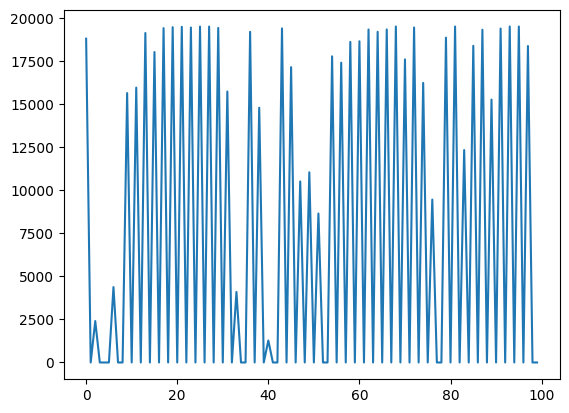

In [10]:
import matplotlib.pyplot as plt
powerlst = []
voltlst = []
for i in range(1):
    obs = env.reset()
    print(env.buf_infos)
    for j in range(100):
        action, _states = model.predict(obs)
        obs, rewards, dones, info = env.step(action)
#         print(obs['Power'][0])
        powerlst.append(obs['Power'][0])
        voltlst.append(obs['Voltage'][0])
#         print(rewards)
    plt.plot(powerlst)
    print() 